# A/B Testing & Causal Impact Analysis — Multi-brand Car Service Chain

**Purpose:** A reusable end-to-end Python notebook for experiment design, data-quality checks, A/B test analysis, historical Difference-in-Differences (DiD), segmentation, and CUPED/regression adjustment.

> **Important:** No source datasets were attached when this notebook was created. This is a complete analysis template, not a report containing invented results. Set the file paths and column mappings in **Section 1** to match the supplied files. The notebook deliberately stops with a clear error when required fields are not mapped.

## Analysis plan
1. Configure files and column names.
2. Load and profile vehicle sales, service job cards, warranty claims, experiment data, and historical regional data.
3. Clean and construct service-visit outcomes.
4. Design the prospective A/B test and calculate sample size / duration.
5. Check randomisation balance and sample-ratio mismatch.
6. Estimate experiment effects with confidence intervals.
7. Estimate historical impact using DiD and assess pre-trends.
8. Segment treatment effects.
9. Apply CUPED / regression adjustment and estimate the potential sample-size reduction.
10. Export tables and a decision memo draft.

**Unit-of-analysis warning:** Choose the unit that was actually randomised (customer, vehicle, service visit, or dealership). Standard errors and bootstrap resampling must respect that unit. If dealerships were randomised, 18 dealerships is a small number of clusters; ordinary row-level tests are not valid substitutes for cluster-aware inference.

## 1. Configuration

Put the CSV/Excel files in the same folder as this notebook, or update the paths below.

The notebook supports two ways of working:

- **Preferred:** use the provided experiment dataset and historical panel dataset if your project provider supplied them.
- **Fallback:** load the raw sales, job-card and warranty files, map their columns, and build a visit-level table.

Column names vary between providers. Update the mappings below to match your files. Do not guess a join key: verify that the vehicle ID and job-card / claim relationships are correct.

In [17]:
from pathlib import Path
import warnings
import math
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    proportions_ztest, proportion_confint, proportion_effectsize
)
from statsmodels.stats.contingency_tables import Table2x2
import statsmodels.formula.api as smf
import statsmodels.api as sm

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# ---- FILE PATHS: edit these ----
FILES = {
    "sales": "noida_vehicle_sales.csv",
    "jobs": "service_job_cards.csv",
    "claims": "warranty_claims.csv",
    "experiment": "experiment_dataset.csv",
    "historical": "historical_region_panel.csv",
    "part_map": "part_code_mapping.csv",  # optional: old_part_code,new_part_code
}

# ---- RAW TABLE COLUMN MAPPINGS: edit values to match your files ----
# Use None for a field that does not exist in that source.
COLS = {
    "sales": {
        "vehicle_id": "vehicle_id",
        "sale_date": "sale_date",
        "brand": "brand",
        "model": "model",
        "sale_dealership_id": "dealership_id",
    },
    "jobs": {
        "job_id": "job_card_id",
        "vehicle_id": "vehicle_id",
        "dealership_id": "dealership_id",
        "visit_date": "job_card_date",
        "odometer": "odometer_reading",
        "service_revenue": "service_revenue",
        "service_type": "service_type",
        "part_code": "part_code",
        "customer_id": "customer_id",
    },
    "claims": {
        "claim_id": "claim_id",
        "job_id": "job_card_id",       # if claims link to job cards
        "vehicle_id": "vehicle_id",
        "claim_date": "claim_date",
        "failure_code": "failure_code",
        "part_code": "part_code",
    },
}

# ---- EXPERIMENT DATASET MAPPING ----
# Expected: one row per analysis unit (ideally vehicle/customer or randomised unit).
# ---- EXPERIMENT DATASET MAPPING ----
EXP = {
    "unit_id": "vehicle_id",
    "group": "treatment_group",         # Updated to match 'treatment_group'
    "dealership_id": "dealership_id",
    "warranty_claim": "warranty_claim_flag", # Updated to match 'warranty_claim_flag'
    "repeat_repair": "repeat_visit_30d",     # Map if applicable, or set to None
    "service_revenue": "post_revenue_inr",   # Updated to match 'post_revenue_inr'
    "pre_revenue": "baseline_spend_inr",     # Updated to match 'baseline_spend_inr'
    "vehicle_age": "vehicle_age_years",      # Updated to match 'vehicle_age_years'
    "brand": "brand",                        # If brand exists, else None
    "service_type": "service_type",          # If service_type exists, else None
    "pre_warranty_claim": None,              # Set to None if not present
}

# ---- HISTORICAL PANEL DATASET MAPPING ----
# Expected: one row per dealership-period (or equivalent aggregated region-period).
# ---- HISTORICAL PANEL DATASET MAPPING ----
HIST = {
    "period": "period",                      # date or period label
    "region": "region",
    "dealership_id": "dealership_id",
    "treated_region": "treatment_status",    # Updated to match 'treatment_status'
    "post": "post_period",                   # Updated to match 'post_period'
    "outcome": "warranty_claim_rate",        # Updated to match 'warranty_claim_rate'
    "visits": "service_visits",              # optional denominator for weighted models
}

# ---- DESIGN ASSUMPTIONS: replace with project-approved values ----
DESIGN = {
    "baseline_claim_rate": 0.08,
    "target_absolute_reduction": 0.01, # 1 percentage point reduction
    "alpha": 0.05,
    "power": 0.80,
    "allocation_ratio": 1.0,            # treatment / control
    "eligible_units_per_day": 500,      # combined daily eligible units; replace
    "followup_days": 60,                # warranty outcome maturation window; replace
    "randomisation_unit": "vehicle",    # vehicle / customer / dealership
    "intracluster_correlation": 0.02,   # only used for cluster design effect; estimate if possible
    "average_cluster_size": 100,        # replace with actual cluster size
}

OUTPUT_DIR = Path("ab_test_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Working directory:", Path.cwd())
print("Output directory:", OUTPUT_DIR.resolve())

Working directory: /content
Output directory: /content/ab_test_outputs


## 2. Utility functions and safe loading

In [2]:
def read_table(path):
    path = Path(path)
    if not path.exists():
        print(f"Not found (optional until needed): {path}")
        return None
    if path.suffix.lower() in [".xlsx", ".xls"]:
        return pd.read_excel(path)
    return pd.read_csv(path)

def require_columns(df, mapping, table_name):
    missing = [source for source in mapping.values()
               if source is not None and source not in df.columns]
    if missing:
        raise KeyError(f"{table_name}: mapped columns not found: {missing}. "
                       f"Available columns: {list(df.columns)}")

def standardise_columns(df, mapping):
    """Return a copy with canonical column names for mapped source fields."""
    reverse = {source: canonical for canonical, source in mapping.items()
               if source is not None and source in df.columns}
    return df.rename(columns=reverse).copy()

def pct(x):
    return 100 * x

def ci_mean(x, confidence=0.95):
    x = pd.Series(x).dropna().astype(float)
    n = len(x)
    if n < 2:
        return (np.nan, np.nan)
    mean = x.mean()
    se = stats.sem(x)
    q = stats.t.ppf((1 + confidence) / 2, n - 1)
    return mean - q * se, mean + q * se

def bootstrap_difference(a, b, statistic=np.mean, n_boot=5000,
                         confidence=0.95, seed=RANDOM_SEED):
    """Independent-unit percentile bootstrap: returns B-A and percentile CI."""
    a = np.asarray(pd.Series(a).dropna())
    b = np.asarray(pd.Series(b).dropna())
    if len(a) < 2 or len(b) < 2:
        return np.nan, np.nan, np.nan
    local_rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        aa = local_rng.choice(a, size=len(a), replace=True)
        bb = local_rng.choice(b, size=len(b), replace=True)
        diffs[i] = statistic(bb) - statistic(aa)
    estimate = statistic(b) - statistic(a)
    lo = np.quantile(diffs, (1-confidence)/2)
    hi = np.quantile(diffs, 1-(1-confidence)/2)
    return estimate, lo, hi

def standardised_mean_difference(x_t, x_c):
    x_t = pd.Series(x_t).dropna().astype(float)
    x_c = pd.Series(x_c).dropna().astype(float)
    pooled_sd = np.sqrt((x_t.var(ddof=1) + x_c.var(ddof=1)) / 2)
    if pooled_sd == 0 or np.isnan(pooled_sd):
        return np.nan
    return (x_t.mean() - x_c.mean()) / pooled_sd

def normalise_group(series):
    s = series.astype(str).str.strip().str.lower()
    treatment_names = {"treatment", "treated", "b", "1", "test"}
    control_names = {"control", "ctrl", "a", "0", "holdout"}
    mapped = s.map(lambda x: "Treatment" if x in treatment_names
                   else ("Control" if x in control_names else np.nan))
    if mapped.isna().any():
        unknown = sorted(s[mapped.isna()].unique())
        raise ValueError(f"Unrecognised experiment group labels: {unknown}. "
                         "Edit normalise_group() to match your labels.")
    return mapped

## 3. Load and profile source datasets

This section reports table sizes, duplicate rows, missingness and date ranges. It does not silently delete records.

In [3]:
sales_raw = read_table(FILES["sales"])
jobs_raw = read_table(FILES["jobs"])
claims_raw = read_table(FILES["claims"])
experiment_raw = read_table(FILES["experiment"])
historical_raw = read_table(FILES["historical"])
part_map_raw = read_table(FILES["part_map"])

tables = {
    "sales": sales_raw, "jobs": jobs_raw, "claims": claims_raw,
    "experiment": experiment_raw, "historical": historical_raw
}

profile_rows = []
for name, df in tables.items():
    if df is None:
        continue
    profile_rows.append({
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_full_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_pct": round(100 * df.isna().sum().sum() /
                             max(df.shape[0] * df.shape[1], 1), 2)
    })
display(pd.DataFrame(profile_rows))

for name, df in tables.items():
    if df is not None:
        print(f"\n{name.upper()} — shape {df.shape}")
        display(df.head(3))

,table,rows,columns,duplicate_full_rows,missing_cells,missing_pct
0,sales,80000,5,0,0,0.0
1,jobs,65000,7,0,0,0.0
2,claims,80000,5,0,14413,3.6
3,experiment,45000,11,0,0,0.0
4,historical,72,9,0,0,0.0



SALES — shape (80000, 5)


,vin,dealership_id,model,sale_date,vehicle_price_inr
0,MA3E10000000,NOIDA_D02,City,2025-01-31,751144
1,MA3E10000001,NOIDA_D15,Venue,2025-12-30,1716039
2,MA3E10000002,NOIDA_D16,Venue,2024-05-10,1751120



JOBS — shape (65000, 7)


,job_card_id,vehicle_id,dealership_id,service_date,odometer,revenue,part_code
0,JC_0000001,VEH_000001,NOIDA_D02,2025-04-16,371,8577.67,PART_OLD_105
1,JC_0000002,VEH_000002,NOIDA_D14,2025-10-29,27909,6203.80,PART_OLD_102
2,JC_0000003,VEH_000006,NOIDA_D16,2025-08-14,57545,6430.86,PART_OLD_102



CLAIMS — shape (80000, 5)


,claim_id,vehicle_id,job_card_id,claim_date,failure_code
0,CLM_000001,VEH_15796,JC_417952,2026-06-11,FC-TRN-02
1,CLM_000002,VEH_00861,JC_279435,2026-06-11,FC-TRN-02
2,CLM_000003,VEH_76821,JC_215779,2025-07-08,FC-ENG-02



EXPERIMENT — shape (45000, 11)


,vehicle_id,treatment_group,dealership_id,region,vehicle_age_years,baseline_spend_inr,baseline_visits,post_revenue_inr,post_visits,repeat_visit_30d,warranty_claim_flag
0,VEH_000001,treatment,NOIDA_D02,Noida_Central,1.25,5163.73,3,5319.47,3,0,0
1,VEH_000002,control,NOIDA_D14,Noida_Central,2.37,6487.50,2,6592.49,0,0,0
2,VEH_000003,control,NOIDA_D12,Noida_Sector62,1.30,7964.15,8,8030.80,2,0,0



HISTORICAL — shape (72, 9)


,region,period,post_period,treatment_group,treatment_status,job_cards_count,avg_revenue_inr,repeat_visit_rate,warranty_claim_rate
0,Noida Sector 18,2024-Q1,0,Treatment,0,5897,7417.03,0.1127,0.0629
1,Noida Sector 18,2024-Q2,0,Treatment,0,6667,8352.79,0.1143,0.0639
2,Noida Sector 18,2024-Q3,0,Treatment,0,6913,8586.00,0.1075,0.0653


## 4. Clean and harmonise raw records

### Data-quality policy
- **Part codes:** use a verified crosswalk from the supplier transition. Never infer that two codes are equivalent solely because their strings look similar.
- **Missing failure codes:** retain missingness as missing; quantify it by time, supplier, dealership and treatment status. Do not invent a failure diagnosis.
- **Backwards odometer:** flag decreases within a vehicle's chronological history. Do not automatically overwrite the reading. Resolve only against a trusted source; otherwise exclude the invalid reading from analyses that require odometer.
- **Duplicates:** investigate business keys (job ID / claim ID), not only exact duplicate rows.

In [4]:
# Standardise raw table names if the files exist.
sales = standardise_columns(sales_raw, COLS["sales"]) if sales_raw is not None else None
jobs = standardise_columns(jobs_raw, COLS["jobs"]) if jobs_raw is not None else None
claims = standardise_columns(claims_raw, COLS["claims"]) if claims_raw is not None else None

if jobs is not None:
    for col in ["visit_date", "odometer", "service_revenue"]:
        if col in jobs.columns:
            jobs[col] = pd.to_numeric(jobs[col], errors="coerce") if col != "visit_date" else pd.to_datetime(jobs[col], errors="coerce")
    if "visit_date" in jobs:
        jobs = jobs.sort_values(["vehicle_id", "visit_date"])
    if "job_id" in jobs:
        print("Duplicate job IDs:", jobs["job_id"].duplicated().sum())
    if "vehicle_id" in jobs and "odometer" in jobs:
        jobs["previous_odometer"] = jobs.groupby("vehicle_id")["odometer"].shift(1)
        jobs["odometer_backwards_flag"] = (
            jobs["odometer"].notna() & jobs["previous_odometer"].notna() &
            (jobs["odometer"] < jobs["previous_odometer"])
        )
        print("Backwards odometer records:", int(jobs["odometer_backwards_flag"].sum()))

if claims is not None:
    if "claim_date" in claims:
        claims["claim_date"] = pd.to_datetime(claims["claim_date"], errors="coerce")
    if "claim_id" in claims:
        print("Duplicate claim IDs:", claims["claim_id"].duplicated().sum())
    if "failure_code" in claims:
        print("Missing failure-code rate:", round(claims["failure_code"].isna().mean(), 4))

# Apply an explicitly supplied part-code crosswalk, if present.
if part_map_raw is not None and jobs is not None and "part_code" in jobs.columns:
    required_map_cols = {"old_part_code", "new_part_code"}
    if required_map_cols.issubset(part_map_raw.columns):
        part_crosswalk = dict(zip(part_map_raw["old_part_code"].astype(str),
                                  part_map_raw["new_part_code"].astype(str)))
        jobs["part_code_original"] = jobs["part_code"]
        jobs["part_code_standard"] = jobs["part_code"].astype(str).map(part_crosswalk).fillna(jobs["part_code"].astype(str))
        print("Part-code crosswalk applied. Unmapped job-card codes:",
              int(~jobs["part_code"].astype(str).isin(part_crosswalk).sum()))
    else:
        print("Part mapping file must contain old_part_code and new_part_code.")
elif jobs is not None and "part_code" in jobs.columns:
    jobs["part_code_standard"] = jobs["part_code"].astype(str)
    print("No crosswalk supplied: part codes retained as recorded; historical comparability is not established.")

if claims is not None and "failure_code" in claims.columns:
    claims["failure_code_missing"] = claims["failure_code"].isna()

display(jobs.head() if jobs is not None else pd.DataFrame())

Duplicate job IDs: 0
Backwards odometer records: 340
Duplicate claim IDs: 0
Missing failure-code rate: 0.1802
Part-code crosswalk applied. Unmapped job-card codes: -1


,job_id,vehicle_id,dealership_id,service_date,odometer,revenue,part_code,previous_odometer,odometer_backwards_flag,part_code_original,part_code_standard
0,JC_0000001,VEH_000001,NOIDA_D02,2025-04-16,371,8577.67,PART_OLD_105,NaN,False,PART_OLD_105,PART_OLD_105
1,JC_0000002,VEH_000002,NOIDA_D14,2025-10-29,27909,6203.80,PART_OLD_102,NaN,False,PART_OLD_102,PART_OLD_102
2,JC_0000003,VEH_000006,NOIDA_D16,2025-08-14,57545,6430.86,PART_OLD_102,NaN,False,PART_OLD_102,PART_OLD_102
3,JC_0000004,VEH_000006,NOIDA_D16,2026-09-08,59297,2767.77,PART_NEW_902,57545.0,False,PART_NEW_902,PART_NEW_902
4,JC_0000005,VEH_000007,NOIDA_D02,2024-09-27,506,3936.41,PART_OLD_101,NaN,False,PART_OLD_101,PART_OLD_101


## 5. Build visit-level outcomes from job cards and claims (if raw data is available)

This produces one row per job card. A claim is linked by job ID when that key exists in both tables; otherwise vehicle-level matching is used only as a fallback and must be reviewed because it may over-link claims.

The claim window must be defined by the business protocol. The simple join below is a record-linkage starting point, not a substitute for a validated warranty follow-up definition.

In [5]:
visit_level = None
if jobs is not None:
    visit_level = jobs.copy()
    if claims is not None:
        if "job_id" in jobs.columns and "job_id" in claims.columns:
            claim_counts = claims.groupby("job_id").size().rename("claim_count")
            visit_level = visit_level.merge(claim_counts, on="job_id", how="left")
        elif "vehicle_id" in jobs.columns and "vehicle_id" in claims.columns:
            print("WARNING: linking claims by vehicle_id only. Add a validated date/window rule before causal analysis.")
            claim_counts = claims.groupby("vehicle_id").size().rename("claim_count_vehicle")
            visit_level = visit_level.merge(claim_counts, on="vehicle_id", how="left")
            visit_level["claim_count"] = visit_level["claim_count_vehicle"]
        else:
            print("No common claim/job key found; warranty outcome not constructed.")
    if "claim_count" in visit_level.columns:
        visit_level["warranty_claim"] = (visit_level["claim_count"].fillna(0) > 0).astype(int)
    if "odometer_backwards_flag" in visit_level.columns:
        visit_level["odometer_valid_for_analysis"] = ~visit_level["odometer_backwards_flag"]
    else:
        visit_level["odometer_valid_for_analysis"] = True

    if "vehicle_id" in visit_level and "visit_date" in visit_level:
        visit_level = visit_level.sort_values(["vehicle_id", "visit_date"])
        visit_level["previous_visit_date"] = visit_level.groupby("vehicle_id")["visit_date"].shift(1)
        # Define repeat repair only after confirming the operational definition with the project owner.
        visit_level["days_since_previous_visit"] = (
            visit_level["visit_date"] - visit_level["previous_visit_date"]
        ).dt.days

    visit_level.to_csv(OUTPUT_DIR / "visit_level_constructed.csv", index=False)
    print("Constructed visit-level table:", visit_level.shape)
    display(visit_level.head())
else:
    print("Raw job-card file not available; skip visit-level construction.")

Constructed visit-level table: (65000, 14)


,job_id,vehicle_id,dealership_id,service_date,odometer,revenue,part_code,previous_odometer,odometer_backwards_flag,part_code_original,part_code_standard,claim_count,warranty_claim,odometer_valid_for_analysis
0,JC_0000001,VEH_000001,NOIDA_D02,2025-04-16,371,8577.67,PART_OLD_105,NaN,False,PART_OLD_105,PART_OLD_105,NaN,0,True
1,JC_0000002,VEH_000002,NOIDA_D14,2025-10-29,27909,6203.80,PART_OLD_102,NaN,False,PART_OLD_102,PART_OLD_102,NaN,0,True
2,JC_0000003,VEH_000006,NOIDA_D16,2025-08-14,57545,6430.86,PART_OLD_102,NaN,False,PART_OLD_102,PART_OLD_102,NaN,0,True
3,JC_0000004,VEH_000006,NOIDA_D16,2026-09-08,59297,2767.77,PART_NEW_902,57545.0,False,PART_NEW_902,PART_NEW_902,NaN,0,True
4,JC_0000005,VEH_000007,NOIDA_D02,2024-09-27,506,3936.41,PART_OLD_101,NaN,False,PART_OLD_101,PART_OLD_101,NaN,0,True


## 6. Missingness and data-quality diagnostics

Compare missingness by dealership / time / group where possible. Differential missingness between treatment and control can bias the estimated effect.

In [6]:
def missingness_report(df, group_col=None):
    if df is None:
        return None
    report = pd.DataFrame({
        "missing_n": df.isna().sum(),
        "missing_pct": 100 * df.isna().mean(),
        "dtype": df.dtypes.astype(str)
    }).sort_values("missing_pct", ascending=False)
    display(report)
    if group_col and group_col in df.columns:
        display(df.groupby(group_col).apply(
            lambda x: x.isna().mean(), include_groups=False
        ).T)
    return report

if jobs is not None:
    print("JOB CARD MISSINGNESS")
    jobs_missing = missingness_report(jobs)
if claims is not None:
    print("CLAIM MISSINGNESS")
    claims_missing = missingness_report(claims)

JOB CARD MISSINGNESS


,missing_n,missing_pct,dtype
previous_odometer,34397,52.918462,float64
vehicle_id,0,0.000000,object
job_id,0,0.000000,object
dealership_id,0,0.000000,object
service_date,0,0.000000,object
revenue,0,0.000000,float64
odometer,0,0.000000,int64
part_code,0,0.000000,object
odometer_backwards_flag,0,0.000000,bool
part_code_original,0,0.000000,object


CLAIM MISSINGNESS


,missing_n,missing_pct,dtype
failure_code,14413,18.01625,object
claim_id,0,0.00000,object
vehicle_id,0,0.00000,object
job_id,0,0.00000,object
claim_date,0,0.00000,datetime64[ns]
failure_code_missing,0,0.00000,bool


## 7. Prospective A/B test design and power analysis

### Example initiative
Enhanced service quality checks and proactive maintenance recommendations.

- **Treatment:** enhanced inspection + documented proactive recommendations.
- **Control:** current standard service process.
- **Primary outcome:** whether an eligible service visit has at least one warranty claim within the pre-specified follow-up window.
- **Secondary outcomes:** repeat-repair rate and service revenue per visit.
- **Guardrails:** customer complaints, service duration, cancellations, refunds, revenue / visit and safety-related rework.

The example design inputs below are placeholders. Replace them with baseline rates from the historical data and a minimum business-relevant effect agreed with stakeholders.

For a binary outcome, the function below calculates the approximate sample size per arm for two independent proportions. If allocation is by dealership, use a cluster design effect as a rough planning adjustment and recognise that a small number of clusters requires specialist methods / simulation.

In [7]:
def two_proportion_sample_size(p_control, p_treatment, alpha=0.05, power=0.80,
                               allocation_ratio=1.0):
    """Approximate normal-theory sample size. Returns control and treatment n."""
    if not (0 < p_control < 1 and 0 < p_treatment < 1):
        raise ValueError("Rates must be strictly between 0 and 1.")
    effect = proportion_effectsize(p_treatment, p_control)
    n_control = NormalIndPower().solve_power(
        effect_size=abs(effect), power=power, alpha=alpha,
        ratio=allocation_ratio, alternative="two-sided"
    )
    n_treatment = n_control * allocation_ratio
    return math.ceil(n_control), math.ceil(n_treatment)

p0 = DESIGN["baseline_claim_rate"]
absolute_reduction = DESIGN["target_absolute_reduction"]
p1 = p0 - absolute_reduction
if p1 <= 0:
    raise ValueError("Target reduction is too large for the selected baseline rate.")

n_c, n_t = two_proportion_sample_size(
    p0, p1, DESIGN["alpha"], DESIGN["power"], DESIGN["allocation_ratio"]
)

# Cluster design effect: approximate planning adjustment only.
m = DESIGN["average_cluster_size"]
icc = DESIGN["intracluster_correlation"]
design_effect = 1 + (m - 1) * icc
if DESIGN["randomisation_unit"] == "dealership":
    n_c_cluster = math.ceil(n_c * design_effect)
    n_t_cluster = math.ceil(n_t * design_effect)
else:
    n_c_cluster, n_t_cluster = n_c, n_t

total_n = n_c_cluster + n_t_cluster
daily_total = DESIGN["eligible_units_per_day"]
recruitment_days = math.ceil(total_n / daily_total) if daily_total > 0 else np.nan
estimated_calendar_days = recruitment_days + DESIGN["followup_days"]

power_summary = pd.DataFrame([{
    "control_rate": p0,
    "treatment_rate_assumed": p1,
    "absolute_effect": p1-p0,
    "relative_effect_pct": 100*(p1-p0)/p0,
    "alpha": DESIGN["alpha"],
    "power": DESIGN["power"],
    "n_control_unadjusted": n_c,
    "n_treatment_unadjusted": n_t,
    "design_effect": design_effect if DESIGN["randomisation_unit"] == "dealership" else 1,
    "n_control_planned": n_c_cluster,
    "n_treatment_planned": n_t_cluster,
    "total_planned_n": total_n,
    "recruitment_days": recruitment_days,
    "followup_days": DESIGN["followup_days"],
    "estimated_total_days": estimated_calendar_days
}])
display(power_summary)
power_summary.to_csv(OUTPUT_DIR / "power_analysis.csv", index=False)

print("Caution: a design effect does not solve the few-cluster problem. With only 18 dealerships, cluster-randomised power and inference should be evaluated using cluster-level simulation / small-sample methods.")

,control_rate,treatment_rate_assumed,absolute_effect,relative_effect_pct,alpha,power,n_control_unadjusted,n_treatment_unadjusted,design_effect,n_control_planned,n_treatment_planned,total_planned_n,recruitment_days,followup_days,estimated_total_days
0,0.08,0.07,-0.01,-12.5,0.05,0.8,10879,10879,1,10879,10879,21758,44,60,104


Caution: a design effect does not solve the few-cluster problem. With only 18 dealerships, cluster-randomised power and inference should be evaluated using cluster-level simulation / small-sample methods.


### Randomisation recommendation

If treatment can be delivered at the vehicle/customer level without spillover, randomise eligible vehicles or customers within dealership, stratifying by dealership and possibly vehicle brand. This improves balance across the 18 sites.

If the initiative changes dealership-wide workflow, randomise dealerships (ideally matched pairs), not individual visits. With only 18 dealerships, power may be poor; consider more regions / dealerships, a longer test, or a stepped-wedge design. Do not randomise at the visit level if the same vehicle can cross between arms.

## 8. Load and prepare the experiment dataset

Expected fields: randomisation unit ID, group, dealership, primary outcome (0/1), secondary binary outcome (0/1), revenue, and pre-period covariates. Map the real file columns in Section 1.

In [10]:
exp = None
if experiment_raw is not None:
    exp = standardise_columns(experiment_raw, EXP)
    required = ["unit_id", "group", "warranty_claim"]
    missing = [c for c in required if c not in exp.columns]
    if missing:
        raise KeyError(f"Experiment data is missing required mapped fields: {missing}. Update EXP.")
    exp["group"] = normalise_group(exp["group"])
    exp["warranty_claim"] = pd.to_numeric(exp["warranty_claim"], errors="coerce")
    if not set(exp["warranty_claim"].dropna().unique()).issubset({0, 1}):
        raise ValueError("warranty_claim must be coded 0/1.")
    for col in ["repeat_repair", "service_revenue", "pre_revenue",
                "vehicle_age", "pre_warranty_claim"]:
        if col in exp.columns:
            exp[col] = pd.to_numeric(exp[col], errors="coerce")
    print("Experiment dataset:", exp.shape)
    display(exp.groupby("group").size().rename("n"))
else:
    print("Experiment file not found. Add it and rerun from this section.")

Experiment dataset: (45000, 11)


,n
group,
Control,22568
Treatment,22432


## 9. Sample Ratio Mismatch (SRM)

For a planned 50:50 split, compare observed counts with expected counts using a chi-square goodness-of-fit test. For a different planned allocation, change `expected_share_treatment`.

In [11]:
if exp is not None:
    expected_share_treatment = 0.50
    counts = exp["group"].value_counts().reindex(["Control", "Treatment"], fill_value=0)
    observed = np.array([counts["Control"], counts["Treatment"]], dtype=float)
    total = observed.sum()
    expected = np.array([total*(1-expected_share_treatment),
                         total*expected_share_treatment])
    chi2 = (((observed-expected)**2)/expected).sum()
    srm_p = stats.chi2.sf(chi2, df=1)
    srm_result = pd.DataFrame({
        "group": ["Control", "Treatment"],
        "observed": observed.astype(int),
        "expected": expected,
        "observed_share": observed/total
    })
    display(srm_result)
    print(f"SRM chi-square={chi2:.4f}, p-value={srm_p:.6g}")
    if srm_p < 0.001:
        print("ALERT: strong evidence of sample-ratio mismatch. Investigate assignment, eligibility, logging and exclusions before effect analysis.")
    else:
        print("No strong SRM signal at the 0.001 diagnostic threshold. This does not prove randomisation was implemented correctly.")

,group,observed,expected,observed_share
0,Control,22568,22500.0,0.501511
1,Treatment,22432,22500.0,0.498489


SRM chi-square=0.4110, p-value=0.521451
No strong SRM signal at the 0.001 diagnostic threshold. This does not prove randomisation was implemented correctly.


## 10. Randomisation balance

Use standardised mean differences (SMDs) for baseline covariates. For categorical variables, compute level-specific proportions and SMDs after one-hot encoding. Balance checks are diagnostics; do not use baseline significance tests as a gate for keeping variables in the analysis.

In [12]:
if exp is not None:
    baseline_numeric = [c for c in ["vehicle_age", "pre_revenue", "pre_warranty_claim"]
                        if c in exp.columns]
    balance_rows = []
    for col in baseline_numeric:
        t = exp.loc[exp.group=="Treatment", col].dropna()
        c = exp.loc[exp.group=="Control", col].dropna()
        balance_rows.append({
            "variable": col, "control_mean": c.mean(), "treatment_mean": t.mean(),
            "SMD": standardised_mean_difference(t, c),
            "control_n": len(c), "treatment_n": len(t)
        })
    if balance_rows:
        balance = pd.DataFrame(balance_rows)
        display(balance)
        balance.to_csv(OUTPUT_DIR / "randomisation_balance.csv", index=False)

    categorical = [c for c in ["brand", "service_type", "dealership_id"] if c in exp.columns]
    for col in categorical:
        tab = pd.crosstab(exp[col].fillna("Missing"), exp["group"], normalize="columns")
        print(f"\n{col}: within-group proportions")
        display(tab)

,variable,control_mean,treatment_mean,SMD,control_n,treatment_n
0,vehicle_age,2.496057,2.500194,0.003592,22568,22432
1,pre_revenue,7164.378520,7183.200066,0.006243,22568,22432



dealership_id: within-group proportions


group,Control,Treatment
dealership_id,,
NOIDA_D01,0.000000,0.113231
NOIDA_D02,0.000000,0.110512
NOIDA_D03,0.000000,0.113989
NOIDA_D04,0.000000,0.109620
NOIDA_D05,0.000000,0.112964
NOIDA_D06,0.000000,0.111537
NOIDA_D07,0.000000,0.107124
NOIDA_D08,0.000000,0.112250
NOIDA_D09,0.000000,0.108773


## 11. Primary A/B effect: warranty claim rate

The estimate is Treatment minus Control. For a desirable reduction, a negative estimate is beneficial. The simple two-proportion z-test and Newcombe/Wilson confidence intervals assume independent analysis units. If assignment was clustered, replace with cluster-level inference or a cluster bootstrap.

In [13]:
def binary_effect_table(df, outcome, group_col="group"):
    d = df[[outcome, group_col]].dropna()
    c = d.loc[d[group_col]=="Control", outcome].astype(int)
    t = d.loc[d[group_col]=="Treatment", outcome].astype(int)
    x = np.array([t.sum(), c.sum()])
    n = np.array([len(t), len(c)])
    z_stat, p_value = proportions_ztest(x, n)
    p_t, p_c = t.mean(), c.mean()
    # Wilson intervals for each arm; difference CI via independent normal approximation.
    ci_t = proportion_confint(t.sum(), len(t), alpha=0.05, method="wilson")
    ci_c = proportion_confint(c.sum(), len(c), alpha=0.05, method="wilson")
    diff = p_t - p_c
    se = np.sqrt(p_t*(1-p_t)/len(t) + p_c*(1-p_c)/len(c))
    diff_ci = (diff - 1.96*se, diff + 1.96*se)
    relative = diff/p_c if p_c != 0 else np.nan
    return pd.DataFrame([{
        "outcome": outcome, "control_n": len(c), "treatment_n": len(t),
        "control_rate": p_c, "treatment_rate": p_t,
        "effect_T_minus_C": diff, "relative_effect": relative,
        "ci95_low": diff_ci[0], "ci95_high": diff_ci[1],
        "z_stat": z_stat, "p_value": p_value,
        "control_rate_ci_low": ci_c[0], "control_rate_ci_high": ci_c[1],
        "treatment_rate_ci_low": ci_t[0], "treatment_rate_ci_high": ci_t[1]
    }])

if exp is not None:
    primary_result = binary_effect_table(exp, "warranty_claim")
    display(primary_result)
    primary_result.to_csv(OUTPUT_DIR / "primary_ab_result.csv", index=False)

,outcome,control_n,treatment_n,control_rate,treatment_rate,effect_T_minus_C,relative_effect,ci95_low,ci95_high,z_stat,p_value,control_rate_ci_low,control_rate_ci_high,treatment_rate_ci_low,treatment_rate_ci_high
0,warranty_claim,22568,22432,0.095046,0.080421,-0.014625,-0.153875,-0.019851,-0.0094,-5.482578,4.191721e-08,0.091288,0.098942,0.076934,0.084052


## 12. Secondary outcomes and bootstrap confidence intervals

For continuous revenue, report mean difference and a Welch t-test. Revenue is often skewed, so also report a bootstrap confidence interval. For binary repeat repair, use the binary effect function above.

In [14]:
if exp is not None and "service_revenue" in exp.columns:
    rev = exp[["group", "service_revenue"]].dropna()
    c = rev.loc[rev.group=="Control", "service_revenue"]
    t = rev.loc[rev.group=="Treatment", "service_revenue"]
    welch = stats.ttest_ind(t, c, equal_var=False)
    est, lo, hi = bootstrap_difference(c, t, statistic=np.mean)
    revenue_result = pd.DataFrame([{
        "control_mean": c.mean(), "treatment_mean": t.mean(),
        "effect_T_minus_C": est, "bootstrap_ci95_low": lo,
        "bootstrap_ci95_high": hi, "welch_t": welch.statistic,
        "welch_p": welch.pvalue, "control_n": len(c), "treatment_n": len(t)
    }])
    display(revenue_result)
    revenue_result.to_csv(OUTPUT_DIR / "revenue_ab_result.csv", index=False)

if exp is not None and "repeat_repair" in exp.columns:
    repeat_result = binary_effect_table(exp, "repeat_repair")
    display(repeat_result)
    repeat_result.to_csv(OUTPUT_DIR / "repeat_repair_ab_result.csv", index=False)

,control_mean,treatment_mean,effect_T_minus_C,bootstrap_ci95_low,bootstrap_ci95_high,welch_t,welch_p,control_n,treatment_n
0,7880.682524,8254.786582,374.104057,306.987805,436.962863,11.093866,1.463628e-28,22568,22432


,outcome,control_n,treatment_n,control_rate,treatment_rate,effect_T_minus_C,relative_effect,ci95_low,ci95_high,z_stat,p_value,control_rate_ci_low,control_rate_ci_high,treatment_rate_ci_low,treatment_rate_ci_high
0,repeat_repair,22568,22432,0.139888,0.110556,-0.029332,-0.209681,-0.035441,-0.023223,-9.398536,5.532763e-21,0.135424,0.144475,0.106519,0.114727


## 13. Cluster-aware bootstrap (when dealerships are the randomisation unit)

When entire dealerships are assigned to treatment or control, resample dealerships within each arm rather than individual rows. This function estimates a difference in dealership-level means. With very few clusters, percentile bootstrap intervals can still be unreliable; report the number of clusters and consider randomisation inference / wild-cluster bootstrap with a statistician.

In [15]:
def cluster_bootstrap_difference(df, outcome, cluster_col="dealership_id",
                                 group_col="group", n_boot=5000, confidence=0.95,
                                 seed=RANDOM_SEED):
    d = df[[cluster_col, group_col, outcome]].dropna().copy()
    cluster_means = d.groupby([group_col, cluster_col])[outcome].mean().reset_index()
    c = cluster_means[cluster_means[group_col]=="Control"][outcome].to_numpy()
    t = cluster_means[cluster_means[group_col]=="Treatment"][outcome].to_numpy()
    if len(c) < 2 or len(t) < 2:
        raise ValueError("Need at least two dealerships in each arm for this bootstrap; more clusters are strongly preferred.")
    estimate = t.mean() - c.mean()
    local_rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)
    for i in range(n_boot):
        boot[i] = local_rng.choice(t, len(t), replace=True).mean() - local_rng.choice(c, len(c), replace=True).mean()
    alpha = 1-confidence
    return {
        "effect_T_minus_C": estimate,
        "ci_low": np.quantile(boot, alpha/2),
        "ci_high": np.quantile(boot, 1-alpha/2),
        "control_clusters": len(c), "treatment_clusters": len(t)
    }

if exp is not None and DESIGN["randomisation_unit"] == "dealership" and "dealership_id" in exp.columns:
    try:
        cluster_result = cluster_bootstrap_difference(exp, "warranty_claim")
        display(pd.DataFrame([cluster_result]))
    except ValueError as e:
        print(e)

## 14. Historical Difference-in-Differences (DiD)

The historical panel should contain multiple pre- and post-change periods for treated and comparable control regions. `treated_region` is 1 for Noida and 0 for the comparison region; `post` is 1 after the change.

The coefficient on `treated_region:post` is the DiD estimate. Use dealership-clustered standard errors if dealerships are the independent assignment / shock units. If the number of clusters is small, conventional cluster-robust p-values can be unreliable.

In [18]:
hist = None
if historical_raw is not None:
    hist = standardise_columns(historical_raw, HIST)
    required = ["period", "region", "treated_region", "post", "outcome"]
    missing = [c for c in required if c not in hist.columns]
    if missing:
        raise KeyError(f"Historical panel missing mapped fields: {missing}. Update HIST.")
    hist["treated_region"] = pd.to_numeric(hist["treated_region"], errors="raise")
    hist["post"] = pd.to_numeric(hist["post"], errors="raise")
    hist["outcome"] = pd.to_numeric(hist["outcome"], errors="coerce")
    hist["period"] = pd.to_datetime(hist["period"], errors="coerce")
    display(hist.head())
else:
    print("Historical panel file not found.")

/tmp/ipykernel_453/2499803970.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  hist["period"] = pd.to_datetime(hist["period"], errors="coerce")


,region,period,post,treatment_group,treated_region,job_cards_count,avg_revenue_inr,repeat_visit_rate,outcome
0,Noida Sector 18,2024-01-01,0,Treatment,0,5897,7417.03,0.1127,0.0629
1,Noida Sector 18,2024-04-01,0,Treatment,0,6667,8352.79,0.1143,0.0639
2,Noida Sector 18,2024-07-01,0,Treatment,0,6913,8586.00,0.1075,0.0653
3,Noida Sector 18,2024-10-01,0,Treatment,0,6488,7945.37,0.1027,0.0698
4,Noida Sector 18,2025-01-01,0,Treatment,0,6094,7272.88,0.0993,0.0681


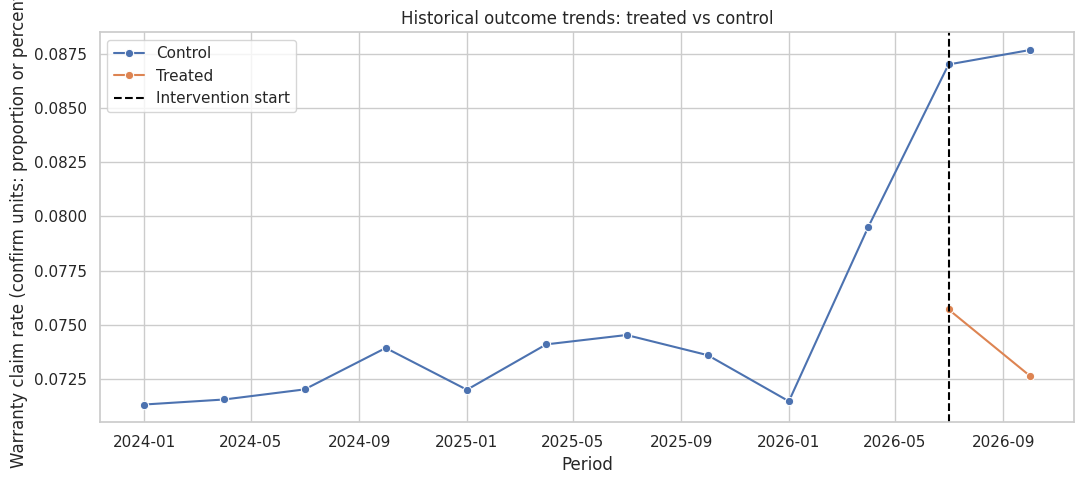

                            OLS Regression Results                            
Dep. Variable:                outcome   R-squared:                       0.237
Model:                            OLS   Adj. R-squared:                  0.215
Method:                 Least Squares   F-statistic:                     12.82
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           1.84e-05
Time:                        15:06:25   Log-Likelihood:                 256.13
No. Observations:                  72   AIC:                            -506.3
Df Residuals:                      69   BIC:                            -499.4
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.0734    

/tmp/ipykernel_453/2075675676.py:20: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  did_model = smf.ols(formula, data=hist).fit(cov_type="HC3")
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 3, but rank is 2
  res = self.wald_test(


In [19]:
if hist is not None:
    trend = hist.groupby(["period", "treated_region"])["outcome"].mean().reset_index()
    trend["region_group"] = trend["treated_region"].map({0:"Control", 1:"Treated"})
    plt.figure(figsize=(11, 5))
    sns.lineplot(data=trend, x="period", y="outcome", hue="region_group", marker="o")
    plt.axvline(hist.loc[hist["post"]==1, "period"].min(), color="black", linestyle="--", label="Intervention start")
    plt.title("Historical outcome trends: treated vs control")
    plt.ylabel("Warranty claim rate (confirm units: proportion or percent)")
    plt.xlabel("Period")
    plt.legend()
    plt.tight_layout()
    plt.show()

    formula = "outcome ~ treated_region + post + treated_region:post"
    if "dealership_id" in hist.columns and hist["dealership_id"].nunique() > 1:
        did_model = smf.ols(formula, data=hist).fit(
            cov_type="cluster", cov_kwds={"groups": hist["dealership_id"]}
        )
    else:
        did_model = smf.ols(formula, data=hist).fit(cov_type="HC3")
    print(did_model.summary())
    did_coef = did_model.params.get("treated_region:post", np.nan)
    did_ci = did_model.conf_int().loc["treated_region:post"].tolist()
    print(f"DiD estimate: {did_coef:.6f}; 95% CI: [{did_ci[0]:.6f}, {did_ci[1]:.6f}]")
    pd.DataFrame([{
        "did_estimate": did_coef, "ci95_low": did_ci[0],
        "ci95_high": did_ci[1], "p_value": did_model.pvalues["treated_region:post"]
    }]).to_csv(OUTPUT_DIR / "did_result.csv", index=False)

## 15. Parallel-trends diagnostic and event study

A pre-trend check uses only pre-intervention periods. A non-significant pre-trend test is not proof that parallel trends holds; graphical and substantive assessment are also required.

The event-study below uses the earliest pre-period as the reference period. Interpret pre-period interaction coefficients as diagnostics and post-period coefficients as dynamic effects, subject to the same assumptions as DiD.

In [20]:
if hist is not None:
    pre = hist[hist["post"] == 0].copy()
    if pre["period"].nunique() >= 2:
        pre["time_index"] = pre["period"].rank(method="dense").astype(int)
        pretrend_model = smf.ols(
            "outcome ~ treated_region * time_index", data=pre
        ).fit(cov_type="cluster" if "dealership_id" in pre.columns else "HC3",
              cov_kwds={"groups": pre["dealership_id"]} if "dealership_id" in pre.columns else None)
        print(pretrend_model.summary())
        print("Pre-trend interaction coefficient:",
              pretrend_model.params.get("treated_region:time_index"))
    else:
        print("Not enough pre-periods to assess parallel trends. Obtain multiple pre-intervention periods.")

    # Event study using period categories; earliest observed period is reference.
    hist = hist.copy()
    hist["period_label"] = hist["period"].dt.strftime("%Y-%m-%d")
    ordered_periods = sorted(hist["period_label"].dropna().unique())
    if len(ordered_periods) >= 3:
        reference_period = ordered_periods[0]
        hist["period_label"] = pd.Categorical(hist["period_label"],
                                                categories=ordered_periods, ordered=True)
        event_formula = f'outcome ~ treated_region * C(period_label, Treatment(reference="{reference_period}"))'
        if "dealership_id" in hist.columns and hist["dealership_id"].nunique() > 1:
            event_model = smf.ols(event_formula, data=hist).fit(
                cov_type="cluster", cov_kwds={"groups": hist["dealership_id"]}
            )
        else:
            event_model = smf.ols(event_formula, data=hist).fit(cov_type="HC3")
        print(event_model.summary())

                            OLS Regression Results                            
Dep. Variable:                outcome   R-squared:                       0.041
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     1.998
Date:                Sat, 07 Nov 2026   Prob (F-statistic):              0.163
Time:                        15:06:32   Log-Likelihood:                 211.14
No. Observations:                  60   AIC:                            -418.3
Df Residuals:                      58   BIC:                            -414.1
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

/tmp/ipykernel_453/3634177946.py:7: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(cov_type="cluster" if "dealership_id" in pre.columns else "HC3",
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 3, but rank is 1
  res = self.wald_test(
/tmp/ipykernel_453/3634177946.py:29: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  event_model = smf.ols(event_formula, data=hist).fit(cov_type="HC3")
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 23, but rank is 13
  res = self.wald_test(


## 16. Segment treatment effects

Run segment analyses only for pre-specified, meaningful groups where possible. For each segment, report sample size and confidence interval. Treat these as exploratory unless the analysis plan pre-specified them and adjusted for multiple comparisons.

In [21]:
def segment_binary_effects(df, segment_col, outcome="warranty_claim", min_n=30):
    rows = []
    for segment, g in df.groupby(segment_col, dropna=False):
        c = g.loc[g.group=="Control", outcome].dropna().astype(float)
        t = g.loc[g.group=="Treatment", outcome].dropna().astype(float)
        if len(c) < min_n or len(t) < min_n:
            continue
        p_c, p_t = c.mean(), t.mean()
        diff = p_t-p_c
        se = np.sqrt(p_t*(1-p_t)/len(t) + p_c*(1-p_c)/len(c))
        rows.append({
            "segment": str(segment), "control_n": len(c), "treatment_n": len(t),
            "control_rate": p_c, "treatment_rate": p_t,
            "effect_T_minus_C": diff,
            "ci95_low": diff-1.96*se, "ci95_high": diff+1.96*se
        })
    return pd.DataFrame(rows)

if exp is not None:
    segment_tables = {}
    for seg in ["dealership_id", "brand", "service_type"]:
        if seg in exp.columns:
            res = segment_binary_effects(exp, seg)
            segment_tables[seg] = res
            print(f"Segment results: {seg}")
            display(res)
            res.to_csv(OUTPUT_DIR / f"segment_{seg}.csv", index=False)

Segment results: dealership_id


""


## 17. CUPED variance reduction

CUPED uses a pre-treatment covariate correlated with the outcome. Use only covariates measured before treatment assignment. The code below adjusts the continuous service-revenue outcome using pre-period revenue.

For a binary primary outcome, a regression adjustment / covariate-adjusted risk difference may be more appropriate than mechanically applying a linear CUPED transform. This notebook also shows a simple regression-adjusted model as a sensitivity analysis.

In [22]:
def cuped_adjustment(df, outcome, covariate, group_col="group"):
    d = df[[outcome, covariate, group_col]].dropna().copy()
    theta = d[outcome].cov(d[covariate]) / d[covariate].var()
    xbar = d[covariate].mean()
    d["cuped_outcome"] = d[outcome] - theta*(d[covariate]-xbar)
    return d, theta

if exp is not None and {"service_revenue", "pre_revenue"}.issubset(exp.columns):
    cuped_df, theta = cuped_adjustment(exp, "service_revenue", "pre_revenue")
    raw_var = cuped_df["service_revenue"].var()
    adjusted_var = cuped_df["cuped_outcome"].var()
    variance_reduction = 1-adjusted_var/raw_var if raw_var > 0 else np.nan

    raw_c = cuped_df.loc[cuped_df.group=="Control", "service_revenue"]
    raw_t = cuped_df.loc[cuped_df.group=="Treatment", "service_revenue"]
    adj_c = cuped_df.loc[cuped_df.group=="Control", "cuped_outcome"]
    adj_t = cuped_df.loc[cuped_df.group=="Treatment", "cuped_outcome"]

    raw_effect, raw_lo, raw_hi = bootstrap_difference(raw_c, raw_t)
    adj_effect, adj_lo, adj_hi = bootstrap_difference(adj_c, adj_t)

    cuped_summary = pd.DataFrame([{
        "theta": theta, "raw_variance": raw_var,
        "cuped_variance": adjusted_var,
        "variance_reduction_pct": 100*variance_reduction,
        "raw_effect": raw_effect, "raw_ci_low": raw_lo, "raw_ci_high": raw_hi,
        "cuped_effect": adj_effect, "cuped_ci_low": adj_lo, "cuped_ci_high": adj_hi,
        "approx_sample_size_ratio": adjusted_var/raw_var if raw_var > 0 else np.nan,
        "approx_duration_reduction_pct": 100*variance_reduction
    }])
    display(cuped_summary)
    cuped_summary.to_csv(OUTPUT_DIR / "cuped_summary.csv", index=False)
else:
    print("CUPED skipped: map both service_revenue and pre_period_revenue in EXP.")

# Regression adjustment example for binary warranty outcome.
if exp is not None:
    candidate_covariates = [c for c in ["vehicle_age", "pre_revenue", "pre_warranty_claim"]
                            if c in exp.columns]
    if candidate_covariates:
        formula = "warranty_claim ~ C(group) + " + " + ".join(candidate_covariates)
        reg = smf.ols(formula, data=exp.dropna(subset=["warranty_claim"]+candidate_covariates)).fit(cov_type="HC3")
        print(reg.summary())

,theta,raw_variance,cuped_variance,variance_reduction_pct,raw_effect,raw_ci_low,raw_ci_high,cuped_effect,cuped_ci_low,cuped_ci_high,approx_sample_size_ratio,approx_duration_reduction_pct
0,1.123322,1.282384e+07,1.356498e+06,89.422058,374.104057,306.987805,436.962863,352.961394,331.578337,372.850276,0.105779,89.422058


                            OLS Regression Results                            
Dep. Variable:         warranty_claim   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     10.71
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           4.94e-07
Time:                        15:06:49   Log-Likelihood:                -7022.8
No. Observations:               45000   AIC:                         1.405e+04
Df Residuals:                   44996   BIC:                         1.409e+04
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.09

## 18. Guardrail review

Set business-approved thresholds before examining results. The example below only creates a review table; it does not automatically make a GO decision.

For a metric where higher is better, define the maximum acceptable decline. For a metric where lower is better, define the maximum acceptable increase. Use confidence intervals, not only point estimates.

In [23]:
guardrail_review = pd.DataFrame([
    {"metric": "Service revenue per visit", "direction": "higher_is_better",
     "business_threshold": "Set allowable decline before test", "status": "REVIEW"},
    {"metric": "Repeat-repair rate", "direction": "lower_is_better",
     "business_threshold": "Set allowable increase before test", "status": "REVIEW"},
    {"metric": "Customer complaints", "direction": "lower_is_better",
     "business_threshold": "Set allowable increase before test", "status": "REVIEW"},
    {"metric": "Service duration", "direction": "lower_is_better",
     "business_threshold": "Set allowable increase before test", "status": "REVIEW"},
])
display(guardrail_review)

,metric,direction,business_threshold,status
0,Service revenue per visit,higher_is_better,Set allowable decline before test,REVIEW
1,Repeat-repair rate,lower_is_better,Set allowable increase before test,REVIEW
2,Customer complaints,lower_is_better,Set allowable increase before test,REVIEW
3,Service duration,lower_is_better,Set allowable increase before test,REVIEW


## 19. Decision framework and memo draft

Use the following logic only after verifying data quality, randomisation, outcome maturity, guardrails and assumptions:

- **GO:** primary effect is beneficial, confidence interval excludes no effect (or meets a pre-agreed decision rule), guardrails are acceptable, and no critical validity issue remains.
- **NO-GO:** evidence indicates harm or the initiative fails a pre-agreed minimum business threshold.
- **EXTEND / INCONCLUSIVE:** interval includes both meaningful benefit and meaningful harm, sample size is insufficient, outcome follow-up is immature, or validity diagnostics are unresolved.

Statistical significance alone is not enough. Consider net contribution margin, implementation cost, discount / parts cost, capacity constraints and customer impact.

In [24]:
decision_memo = """
DECISION MEMO — A/B TEST AND HISTORICAL IMPACT

Business question:
Does the new service-quality initiative improve warranty outcomes without damaging financial or customer guardrails?

Experiment design:
- Treatment:
- Control:
- Randomisation unit:
- Primary metric and follow-up window:
- Planned sample size / duration:

Experimental results:
- Control primary rate:
- Treatment primary rate:
- Absolute effect (Treatment - Control):
- 95% confidence interval:
- P-value:
- SRM / balance diagnostics:
- Guardrail results:

Historical DiD:
- DiD estimate:
- 95% confidence interval:
- Parallel-trends evidence:
- Other concurrent changes / limitations:

Segments:
- Groups with evidence of benefit:
- Groups with evidence of harm:
- Multiplicity handling:

CUPED / regression adjustment:
- Variance reduction:
- Approximate sample-size / duration reduction:

Key threats to validity:
- Selection / randomisation problems:
- Missing data / linkage:
- Seasonality / concurrent initiatives:
- Spillovers / contamination:
- Cluster count / inference limitations:

Recommendation: GO / NO-GO / EXTEND

Reason:
Next action:
"""

(OUTPUT_DIR / "decision_memo_template.txt").write_text(decision_memo, encoding="utf-8")
print(decision_memo)


DECISION MEMO — A/B TEST AND HISTORICAL IMPACT

Business question:
Does the new service-quality initiative improve warranty outcomes without damaging financial or customer guardrails?

Experiment design:
- Treatment:
- Control:
- Randomisation unit:
- Primary metric and follow-up window:
- Planned sample size / duration:

Experimental results:
- Control primary rate:
- Treatment primary rate:
- Absolute effect (Treatment - Control):
- 95% confidence interval:
- P-value:
- SRM / balance diagnostics:
- Guardrail results:

Historical DiD:
- DiD estimate:
- 95% confidence interval:
- Parallel-trends evidence:
- Other concurrent changes / limitations:

Segments:
- Groups with evidence of benefit:
- Groups with evidence of harm:
- Multiplicity handling:

CUPED / regression adjustment:
- Variance reduction:
- Approximate sample-size / duration reduction:

Key threats to validity:
- Selection / randomisation problems:
- Missing data / linkage:
- Seasonality / concurrent initiatives:
- Spillov

## 20. Export analysis outputs and final checklist

Before submission, confirm:
- [ ] All column mappings are correct and joins are validated.
- [ ] Part-code crosswalk is supported by a trusted mapping.
- [ ] Missing failure codes and backwards odometers are quantified and handled transparently.
- [ ] Warranty outcome window is mature and consistently defined.
- [ ] Randomisation unit matches the analysis and inference method.
- [ ] SRM and baseline balance are reported.
- [ ] Every key treatment estimate has a confidence interval.
- [ ] DiD has multiple pre-periods and a documented parallel-trends assessment.
- [ ] Segment analysis is labelled exploratory or pre-specified, with multiplicity addressed.
- [ ] CUPED uses pre-treatment data only.
- [ ] Guardrail thresholds and decision rules were set before interpreting outcomes.
- [ ] Decision memo distinguishes statistical from business significance.

The `ab_test_outputs` folder contains the tables and memo template generated by this notebook.

In [25]:
DATA_DIR = Path("/content/sample_data")